## Variables climatiques de saison du projet African Crop Yield Intelligence

Ce notebook contrôle les séries climatiques acquises auprès de NASA POWER, construit les fenêtres de saison de chaque ligne et calcule les indicateurs climatiques de ces fenêtres. Il fait suite à `05_explanatory_variables.ipynb` et relève des phases Data Understanding et Data Preparation de CRISP-DM pour les sources externes.

**Décisions de départ**

- Le climat provient de NASA POWER, seule source sans compte dont le débit permet l'acquisition depuis ce poste. Le porteur du projet a renoncé à Google Earth Engine le 3 novembre 2026.
- Les températures, le point de rosée, le rayonnement et le vent proviennent de MERRA-2 et de CERES. Les précipitations proviennent du produit IMERG diffusé par NASA POWER, pour les raisons établies à la section 3.
- L'estimation a lieu en fin de saison. Chaque indicateur porte donc sur la saison entière, du mois de semis au mois de récolte.

**Préalable**

Les séries doivent avoir été téléchargées par `python -m src.features.climat` et `python -m src.features.climat imerg`, puis réunies dans le magasin de `data/interim/climat`. Les variables sont construites par `python -m src.features.variables`, qui écrit `climat_regional.csv.gz` et `climat_survey.csv.gz` dans `data/processed`. Le notebook relit ces fichiers et en établit les contrôles.

In [1]:
import subprocess
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.data.load import DOSSIER_TRAITE
from src.features.acquisition import REGISTRE
from src.features.calendrier import CULTURES_GGCMI, attribuer_calendrier, calendriers_harveststat, lire_ggcmi
from src.features.climat import DOSSIER_MAGASIN, ouvrir_magasin
from src.features.controles import (
    alignement_regional,
    alignement_survey,
    anomalies_rendement,
    comparer_precipitations,
    cumuls_par_lieu,
    ecart_mois,
    incoherences_annee_semis,
    resumer_power,
    valeur_fenetres,
)
from src.features.geographie import descripteurs_geographiques, zone_survey
from src.features.variables import RECOLTE_ANNEE_DEBUT_SURVEY

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

### 1. Tests unitaires

La suite complète couvre la préparation, le protocole d'évaluation, la géographie, le calendrier, l'agrégation et les indicateurs. Les indicateurs fondés sur l'évapotranspiration sont vérifiés sur les exemples 8 et 18 du bulletin FAO-56.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 74 tests in 1.254s', '', 'OK']


### 2. Intégrité des séries de NASA POWER

Chaque maille de 0,5 degré de latitude sur 0,625 degré de longitude a été téléchargée une fois, compressée et consignée dans le registre avec son empreinte SHA-256. Le contrôle porte sur la structure de chaque fichier, sur les valeurs manquantes et sur les valeurs extrêmes.

In [3]:
registre = pd.read_csv(REGISTRE)
for produit in ["power", "imerg"]:
    fichiers = registre[registre["fichier"].str.startswith(produit + "/")]
    print(f"{produit} : {fichiers['fichier'].nunique()} mailles, {fichiers['octets'].sum() / 1e6:.0f} Mo")

resume = resumer_power()
print("Structure conforme :", int((resume["jours"].eq(15705) & resume["colonnes_conformes"] & resume["dates_uniques"]).sum()),
      "mailles sur", len(resume))
variables = ["T2M_MAX", "T2M_MIN", "T2MDEW", "PRECTOTCORR", "WS2M", "GWETROOT"]
display(pd.DataFrame({
    "mailles avec manquants": [int((resume[f"{v}_manquant"] > 0).sum()) for v in variables],
    "minimum": [resume[f"{v}_min"].min() for v in variables],
    "maximum": [resume[f"{v}_max"].max() for v in variables],
}, index=variables).round(2))
print("Rayonnement manquant après 1984, part maximale par maille :", round(resume["rayonnement_manquant_apres_1984"].max(), 5),
      "| mailles concernées :", int((resume["rayonnement_manquant_apres_1984"] > 0).sum()))
print("Mailles sans aucune valeur de GWETROOT :", resume.loc[resume["GWETROOT_manquant"] == 1, "maille"].tolist())

power : 7363 mailles, 1703 Mo


imerg : 7362 mailles, 207 Mo


Structure conforme : 7363 mailles sur 7363


,mailles avec manquants,minimum,maximum
T2M_MAX,0,-5.19,51.72
T2M_MIN,0,-17.67,37.76
T2MDEW,0,-27.66,29.62
PRECTOTCORR,0,0.00,2580.76
WS2M,0,0.00,18.99
GWETROOT,11,0.08,1.00


Rayonnement manquant après 1984, part maximale par maille : 0.00089 | mailles concernées : 49
Mailles sans aucune valeur de GWETROOT : ['+000.0_+000.000', '+019.0_+038.750', '-000.5_+033.125', '-001.0_+033.125', '-002.5_+041.250', '-007.0_+040.000', '-010.0_+040.625', '-016.5_+043.750', '-025.0_+035.000', '-025.5_+044.375', '-027.0_+033.125']


**Constat**

- Les 7 363 mailles de NASA POWER et les 7 362 mailles d'IMERG ont été acquises sans échec, pour 1 703 Mo et 207 Mo. Chaque fichier POWER couvre les 15 705 jours du 1er janvier 1981 au 31 décembre 2023 avec les sept variables demandées.
- Températures, point de rosée, précipitations et vent sont complets. Le rayonnement manque avant 1984, comme le prévoit CERES, et pour quelques jours isolés de 49 mailles, au plus 0,089 % des jours d'une maille.
- `GWETROOT` manque entièrement pour 11 mailles situées en mer, sur une côte ou sur le lac Victoria. L'une d'elles est centrée sur le point de latitude et de longitude nulles. Elle n'a été téléchargée qu'à cause des positions absentes codées par ce point dans `survey`, et elle n'est plus utilisée.
- Les températures extrêmes restent plausibles, de -17,7 °C sur les hauts plateaux du Lesotho à 51,7 °C dans le Sahara algérien. Le maximum journalier de `PRECTOTCORR` atteint en revanche 2 581 mm.

**Analyse**

La structure des fichiers est conforme. Un cumul de plusieurs milliers de millimètres en un jour est physiquement impossible et justifie l'examen de la section suivante.

### 3. Homogénéité des précipitations

`PRECTOTCORR` est comparé à IMERG, produit satellitaire de précipitations que NASA POWER diffuse à partir de juin 2000. Le cumul annuel moyen des mailles est peu sensible au fait qu'IMERG soit diffusé en temps universel et les autres variables en temps solaire local. `GWETROOT`, humidité du sol calculée par le modèle de surface de MERRA-2 à partir de ses précipitations corrigées, est examiné de la même façon.

Jours de PRECTOTCORR au-delà de 200 mm, toutes mailles, de 1981 à 2019 : 91 au plus par an


,prectotcorr_mm,imerg_mm,rapport,jours_prectotcorr_au_dela_de_200_mm,jours_imerg_au_dela_de_200_mm
2001,630.705,726.937988,0.868,1,8
2002,610.782,723.041016,0.845,0,26
2003,609.557,724.742004,0.841,0,23
2004,640.900,731.315002,0.876,17,34
2005,567.727,683.859009,0.830,0,18
2006,665.765,790.739990,0.842,0,14
2007,767.262,751.304016,1.021,57,29
2008,696.121,735.237976,0.947,9,6
2009,738.585,730.973022,1.010,13,20
2010,767.054,759.465027,1.010,2,19


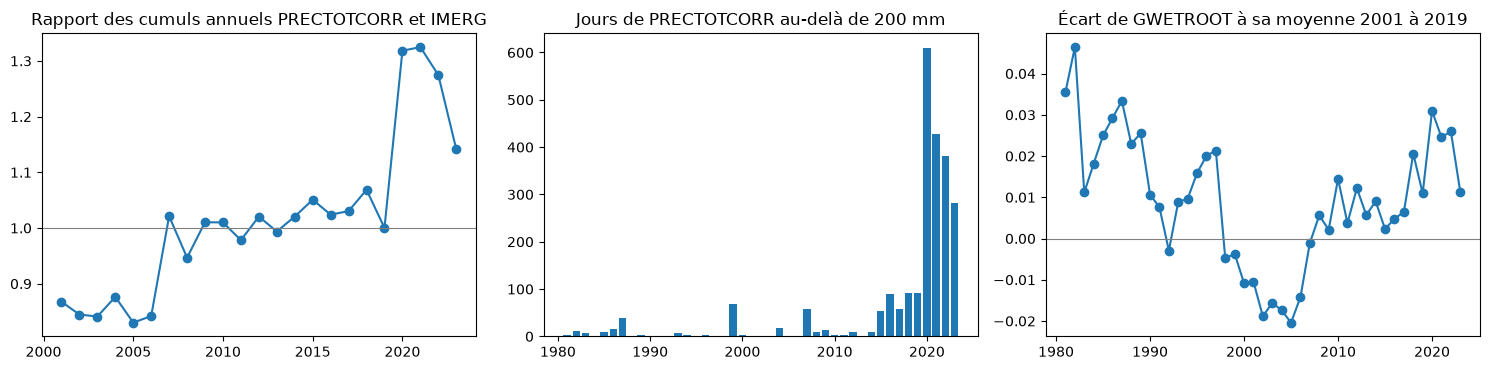

In [4]:
comparaison = comparer_precipitations(resume)
jours = pd.DataFrame(list(resume["jours_aberrants"]), index=resume["maille"]).T.sum(axis=1)
print("Jours de PRECTOTCORR au-delà de 200 mm, toutes mailles, de 1981 à 2019 :", int(jours.loc[:2019].max()), "au plus par an")
display(comparaison.round(3))

gwetroot = pd.DataFrame(list(resume["gwetroot_annuel"]), index=resume["maille"]).T
anomalie = (gwetroot - gwetroot.loc[2001:2019].mean()).mean(axis=1)
figure, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(comparaison.index, comparaison["rapport"], marker="o")
axes[0].axhline(1, color="grey", lw=0.8)
axes[0].set_title("Rapport des cumuls annuels PRECTOTCORR et IMERG")
axes[1].bar(jours.index, jours.values)
axes[1].set_title("Jours de PRECTOTCORR au-delà de 200 mm")
axes[2].plot(anomalie.index, anomalie.values, marker="o")
axes[2].axhline(0, color="grey", lw=0.8)
axes[2].set_title("Écart de GWETROOT à sa moyenne 2001 à 2019")
plt.tight_layout()
plt.show()

**Constat**

- Le nombre de jours de `PRECTOTCORR` au-delà de 200 mm, toutes mailles réunies, ne dépasse pas 91 par an de 1981 à 2019. Il atteint 610 en 2020, 427 en 2021, 382 en 2022 et 281 en 2023. IMERG en compte entre 2 et 34 par an, sans tendance.
- Le cumul annuel moyen d'IMERG reste compris entre 650 et 791 mm de 2001 à 2023.
- Le rapport des cumuls de `PRECTOTCORR` et d'IMERG vaut 0,83 à 0,88 de 2001 à 2006, 0,95 à 1,07 de 2007 à 2019, puis 1,32, 1,33 et 1,28 de 2020 à 2022 et 1,14 en 2023.
- `GWETROOT` atteint en 2020, 2021 et 2022 ses écarts les plus élevés à sa moyenne de 2001 à 2019.

**Analyse**

- L'intensité de `PRECTOTCORR` n'est pas homogène dans le temps. Son excès de 2020 à 2022 tombe dans les périodes futures du protocole, qui commencent en 2017 pour `regional` et comprennent les vagues 2021 et 2022 de `survey`. Un modèle entraîné sur les années antérieures y verrait des saisons artificiellement humides.
- La documentation de NASA POWER ne signale aucun changement de source en 2020, et la cause de la rupture n'est pas identifiée. La comparaison établit l'incohérence de `PRECTOTCORR` sans démontrer l'exactitude d'IMERG, dont la stabilité reste cohérente avec un produit homogène.
- `GWETROOT` hérite de l'excès des précipitations qui forcent le modèle de surface.

**Décisions**

- Les précipitations proviennent d'IMERG. `PRECTOTCORR` et `GWETROOT` ne servent à aucune variable explicative.
- Le stress hydrique est mesuré par le bilan entre les précipitations d'IMERG et l'évapotranspiration de référence FAO-56, calculée dans chaque maille à partir des températures, du point de rosée, du rayonnement, du vent et de l'altitude.

**Conséquences pour la suite**

Les saisons commencées avant juin 2000 n'ont pas d'indicateur de précipitations. Le choix entre restreindre les modèles climatiques aux récoltes postérieures à 2000 et conserver les années antérieures sans précipitations sera tranché par validation croisée.

### 4. Années de semis et de récolte de HarvestStat

Les mois de semis et de récolte ne sont renseignés que pour les lignes `HarvestStat`. L'année de semis publiée est confrontée à celle que déduisent les mois et l'année de récolte, puis l'année de récolte est confrontée à des sécheresses historiques connues.

In [5]:
regional = pd.read_csv(DOSSIER_TRAITE / "regional_modelisation.csv.gz", low_memory=False)
survey = pd.read_csv(DOSSIER_TRAITE / "survey_modelisation.csv.gz", low_memory=False)
incoherences = incoherences_annee_semis(regional)
display(incoherences.sort_values("lignes", ascending=False))
print("Total :", int(incoherences[["semis_publie_trop_tot", "semis_publie_trop_tard"]].sum().sum()), "lignes sur",
      int(regional["planting_month"].notna().sum()))

secheresses = {
    "Malawi, maïs, récolte 1992": anomalies_rendement(regional, "Malawi", "Maize", range(1990, 1995), "Main"),
    "Afrique du Sud, maïs, récolte 1992": anomalies_rendement(regional, "South Africa", "Maize", range(1990, 1995)),
    "Soudan, sorgho, saison 1984": anomalies_rendement(regional, "Sudan", "Sorghum", range(1982, 1987), "Main"),
    "Niger, mil, saison 1984": anomalies_rendement(regional, "Niger", "Millet", range(1982, 1987)),
}
for nom, serie in secheresses.items():
    print(nom, serie.round(2).to_dict())

,lignes,semis_publie_trop_tot,semis_publie_trop_tard
country,,,
Malawi,8531,0,8499
Niger,5844,1382,0
Madagascar,3574,0,3574
Sudan,2181,1959,0
South Africa,1778,0,1301
Mauritania,561,0,272
South Sudan,58,0,58


Total : 17045 lignes sur 118333


Malawi, maïs, récolte 1992 {1990: -0.22, 1991: -0.11, 1992: -1.11, 1993: 0.19, 1994: -0.5}
Afrique du Sud, maïs, récolte 1992 {1990: -0.37, 1991: -0.3, 1992: -0.88, 1993: -0.32, 1994: -0.14}
Soudan, sorgho, saison 1984 {1982: -0.09, 1983: -0.19, 1984: -0.24, 1985: 0.09, 1986: -0.39}
Niger, mil, saison 1984 {1982: 0.01, 1983: -0.04, 1984: -0.45, 1985: 0.1, 1986: 0.06}


**Constat**

- L'année de semis publiée contredit les mois pour 17 045 des 118 333 lignes qui en disposent. Au Malawi, à Madagascar, en Afrique du Sud, en Mauritanie et au Soudan du Sud, un semis de fin d'année et la récolte qui suit portent la même année, ce qui place la récolte avant le semis. Au Soudan et au Niger à partir de 2011, un semis de juin et une récolte de novembre ou de décembre sont séparés d'un an, ce qui produit des saisons de 17 à 18 mois.
- L'année de récolte retrouve les sécheresses connues. Le rendement du maïs s'écarte de -1,11 en logarithme de la moyenne de sa zone pour la récolte de 1992 au Malawi et de -0,88 en Afrique du Sud. La saison 1984 se lit en 1984 au Soudan, à -0,24 contre 0,09 en 1985, et au Niger, à -0,45.

**Analyse**

L'année de récolte est fiable et l'année de semis ne l'est pas. Comme les deux erreurs sont de sens opposés, aucune correction uniforme de l'année de semis n'est possible.

**Décision**

La fenêtre de saison est ancrée sur l'année de récolte. Elle commence l'année précédente lorsque le mois de semis suit le mois de récolte. L'année de semis publiée n'est pas utilisée.

### 5. Alignement des années de `regional` sur le climat

Si la fenêtre de saison est correctement placée, les variations du rendement d'une année à l'autre doivent suivre celles du climat de cette fenêtre. Le test corrèle les différences annuelles du logarithme du rendement avec celles de la température maximale moyenne et du logarithme du cumul de pluie, pour la fenêtre de l'année de récolte et pour les fenêtres décalées d'un an. Les différences retirent les écarts entre zones et les tendances lentes. Les pays de moins de 150 paires de pluie sont omis.

In [6]:
poids_regional = pd.read_csv(DOSSIER_MAGASIN / "poids_regional.csv")
hs = regional[regional["Source"] == "HarvestStat"].reset_index(drop=True)
temperature, dates, _ = cumuls_par_lieu(poids_regional, "power", "T2M_MAX")
pluie, _, debut_imerg = cumuls_par_lieu(poids_regional, "imerg", "IMERG_PRECTOT")
valeurs_t = {d: valeur_fenetres(temperature, dates, hs["GDAM_ID"], hs["harvest_year"] + d,
                                hs["planting_month"], hs["harvest_month"]) for d in [-1, 0, 1]}
valeurs_p = {d: valeur_fenetres(pluie, dates, hs["GDAM_ID"], hs["harvest_year"] + d, hs["planting_month"],
                                hs["harvest_month"], premier_jour=debut_imerg, moyenne=False) for d in [-1, 0, 1]}
table_t = alignement_regional(hs, valeurs_t)
table_p = alignement_regional(hs, valeurs_p, transformation=np.log1p)
alignement = pd.concat({"température": table_t, "pluie": table_p}, axis=1)
alignement = alignement[alignement[("pluie", "paires")] >= 150].sort_values(("température", "paires"), ascending=False)
alignement[("température", "meilleur")] = alignement["température"][[-1, 0, 1]].astype(float).idxmin(axis=1)
alignement[("pluie", "meilleur")] = alignement["pluie"][[-1, 0, 1]].astype(float).idxmax(axis=1)
display(alignement.round(3))

température                       pluie                      température    pluie
decalage                                  -1      0      1 paires     -1      0      1 paires    meilleur meilleur
country                                                                                                           
Benin                                 -0.006 -0.030  0.014  16506  0.014  0.011  0.000  13066           0       -1
Burkina Faso                           0.162 -0.151  0.091   7653 -0.203  0.221 -0.161   4573           0        0
Nigeria                               -0.020  0.024  0.014   7434  0.007 -0.018  0.020   6838          -1        1
Zambia                                 0.063 -0.140  0.140   7171 -0.073  0.080 -0.015   5463           0        0
Malawi                                 0.180 -0.295  0.146   7046  0.020  0.248 -0.164   5282           0        0
Ethiopia                               0.042 -0.088  0.015   5023 -0.057  0.069 -0.027   3881           0        0
Senegal                                0.054 -0.213  0.135   5010 -0.242  0.397 -0.229   2491           0        0
Niger                                  0.207 -0.265  0.144   4466 -0.187  0.254 -0.165   2971           0        0
Kenya                                  0.060 -0.145  0.023   3505  0.005  0.081  0.019   1611           0        0
Madagascar                             0.016 -0.059  0.023   3248  0.011  0.020 -0.046   1296           0        0
Cameroon                              -0.029 -0.075 -0.057   3233 -0.017  0.077 -0.073   2662           0        0
Tanzania                              -0.012 -0.066  0.003   2976 -0.063 -0.022  0.068   1427           0        1
Chad                                   0.234 -0.217  0.142   2463 -0.102  0.118 -0.106   1862           0        0
Angola                                -0.057  0.017 -0.029   1997 -0.018  0.194 -0.109   1857          -1        0
Togo                                  -0.034  0.007 -0.035   1857 -0.005 -0.015  0.009   1450           1        1
South Africa                           0.102 -0.296  0.110   1642 -0.172  0.296 -0.076    990           0        0
Sudan                                  0.149 -0.249  0.072   1638 -0.023  0.104 -0.089    938           0        0
Somalia                                0.052  0.064  0.060   1566  0.021  0.086 -0.203   1282          -1        0
Mali                                   0.020 -0.083  0.048   1486 -0.122  0.101 -0.027    897           0        0
Lesotho                                0.063  0.021 -0.119   1225 -0.143 -0.036  0.191    571           1        1
Mozambique                             0.022 -0.068  0.174   1093 -0.039  0.013 -0.041   1030           0        0
Burundi                                0.114 -0.090 -0.023    453 -0.044  0.007  0.048    453           0        1
Mauritania                            -0.098 -0.078 -0.015    349 -0.127 -0.060  0.048    253          -1        1
Democratic Republic of the Congo      -0.069 -0.076  0.064    225 -0.010  0.030  0.024    225           0        0

**Constat**

- La fenêtre de l'année de récolte donne la corrélation la plus négative avec la température dans 18 des 24 pays, la plus positive avec la pluie dans 17 pays, et les deux à la fois dans 15 pays. Les fenêtres décalées d'un an donnent alors des corrélations de signe opposé ou proches de zéro. Au Sénégal, la corrélation avec la pluie vaut 0,397 pour l'année de récolte, contre -0,242 et -0,229 pour les années voisines.
- L'Éthiopie suit la même règle, avec -0,088 pour la température et 0,069 pour la pluie. Sa saison principale, semée en mai et récoltée en janvier, appartient donc à l'année de récolte de janvier.
- Au Lesotho, les deux variables désignent la fenêtre de l'année suivante, avec -0,119 pour la température et 0,191 pour la pluie, contre 0,021 et -0,036 pour l'année de récolte.
- Dans les 8 autres pays, les deux variables ne désignent pas la même fenêtre ou leurs corrélations restent proches de zéro. C'est notamment le cas au Bénin, au Nigeria et au Togo, où le climat limite peu le rendement.

**Analyse**

L'ancrage sur l'année de récolte et la règle du chevauchement sont validés dans les pays où le climat limite le rendement, et aucun pays autre que le Lesotho ne désigne une autre fenêtre par les deux variables. L'accord des deux variables indépendantes au Lesotho établit que son année de récolte `HarvestStat` désigne en réalité l'année de semis.

**Décision**

Les fenêtres des lignes `HarvestStat` du Lesotho sont décalées d'un an. Les 37 lignes `AgroMAPS` du Lesotho conservent leur année, faute de test.

### 6. Alignement des années de `survey` sur la pluie

`survey` ne publie que le début et la fin de la campagne agricole, toujours séparés d'un an, alors que `annee_recolte` vaut la fin de campagne. Le test compare trois hypothèses sur l'année de récolte réelle, appliquées au calendrier `HarvestStat` de la zone. Les parcelles sont regroupées par zone, culture et vague, et les effets fixes de la zone et de la vague sont retirés, ce qui ne garde que la variation propre à une zone et à une vague. Ce test est moins puissant que celui de `regional`, car un pays ne compte que deux à huit vagues.

In [7]:
tables = calendriers_harveststat(regional)
zones_survey = gpd.read_file(DOSSIER_TRAITE / "zones_survey.gpkg")
survey["zone"] = zone_survey(survey)
survey["crop"] = survey["Crop"].str.strip()
calendrier = attribuer_calendrier(survey, tables, {"zone": "zone", "niveau_1": "L1_GID", "pays": "L0_GID"}, "crop",
                                  [np.nan] * len(survey), [np.nan] * len(survey))
cellules = (
    survey.assign(ly=np.log(survey["YieldUsingGPS_ton_ha_"]), mois_semis=calendrier["mois_semis"],
                  mois_recolte=calendrier["mois_recolte"])
    .dropna(subset=["zone", "mois_semis"])
    .groupby(["Country", "zone", "crop", "AgYearStart", "mois_semis", "mois_recolte"])
    .agg(ly=("ly", "mean"), parcelles=("ly", "size")).reset_index()
)
cellules = cellules[cellules["parcelles"] >= 10]
poids_zones = pd.read_csv(DOSSIER_MAGASIN / "poids_survey.csv")
poids_zones = poids_zones[poids_zones["lieu"].str.startswith("zone:")].assign(lieu=lambda d: d["lieu"].str[5:])
pluie_survey, _, _ = cumuls_par_lieu(poids_zones, "imerg", "IMERG_PRECTOT")
hypotheses = {"récolte en AgYearStart moins un": -1, "récolte en AgYearStart": 0, "récolte en AgYearEnd": 1}
valeurs = {h: valeur_fenetres(pluie_survey, dates, cellules["zone"], cellules["AgYearStart"] + d, cellules["mois_semis"],
                              cellules["mois_recolte"], premier_jour=debut_imerg, moyenne=False)
           for h, d in hypotheses.items()}
display(alignement_survey(cellules, valeurs, transformation=np.log1p).round(3))
print("Pays où la récolte est placée en AgYearStart quel que soit le calendrier :", sorted(RECOLTE_ANNEE_DEBUT_SURVEY))

,récolte en AgYearStart moins un,cellules récolte en AgYearStart moins un,récolte en AgYearStart,cellules récolte en AgYearStart,récolte en AgYearEnd,cellules récolte en AgYearEnd
Country,,,,,,
Ethiopia,0.044,605,0.111,605,-0.016,605
Malawi,-0.046,992,-0.027,992,0.099,992
Mali,-0.273,98,0.026,98,-0.057,98
Niger,-0.053,184,0.103,184,0.217,184
Nigeria,0.053,66,-0.069,66,0.026,66
Senegal,-0.389,20,0.189,20,-0.294,20
Tanzania,0.115,335,0.168,335,0.040,335
Togo,0.020,112,0.273,112,0.130,112
Uganda,-0.095,260,0.077,260,-0.199,260


Pays où la récolte est placée en AgYearStart quel que soit le calendrier : ['Tanzania']


**Constat**

- Au Malawi, la récolte de fin de campagne l'emporte, avec 0,099 contre -0,027. C'est aussi ce que prévoit la règle du chevauchement, la saison allant de novembre à mai.
- En Ouganda, au Togo, au Mali et au Sénégal, la récolte de début de campagne l'emporte. C'est ce que prévoit la règle pour des saisons comprises dans l'année civile.
- En Tanzanie, la récolte de début de campagne l'emporte, avec 0,168 contre 0,040. La règle donnerait la fin de campagne, car le calendrier `HarvestStat` de la plupart des zones est un calendrier annuel de septembre à juillet.
- En Éthiopie, la récolte de début de campagne l'emporte, avec 0,111 contre -0,016, alors que la règle donne la fin de campagne.
- Au Niger, la fin de campagne l'emporte, avec 0,217 contre 0,103 sur 184 cellules.

**Analyse**

- En Tanzanie, le résultat concorde avec la comparaison des rendements de `survey` et de `regional` et avec une enquête qui porte sur la grande saison des pluies récoltée en milieu d'année.
- En Éthiopie, le résultat signifierait que la vague de 2015 mesure la saison principale de 2014, ce qui contredit le déroulement de l'enquête, dont le passage après récolte a lieu au début de l'année de fin de campagne. Le conflit n'est pas résolu ici. Il est levé en faveur de la règle dans `09_cropcut_variables.ipynb`, par les dates de coupe de `cropcut`.
- Au Niger, l'hypothèse de fin de campagne placerait la saison mesurée après l'enquête elle-même, ce qui est impossible. Le signal est attribué au faible nombre de cellules.

**Décisions**

- La saison d'une parcelle commence par le semis de l'année de début de campagne et s'achève à la récolte qui suit, sauf en Tanzanie, où elle s'achève l'année de début de campagne.
- La règle est conservée en Éthiopie et au Niger, et le conflit éthiopien est consigné comme anomalie à réexaminer lors de la modélisation par une analyse de sensibilité.
- `annee_recolte` n'est pas modifiée. Le décalage est constant au sein d'un pays et ne change ni l'ordre des vagues ni les partitions.

### 7. Calendrier des lignes sans mois

Les lignes sans mois reçoivent par ordre de priorité le calendrier `HarvestStat` principal de leur zone, de leur région ou de leur pays pour la même culture, puis le calendrier dominant de leur région ou de leur pays toutes cultures confondues, et enfin le calendrier GGCMI de phase 3 au centroïde de leur lieu. La fiabilité des deux derniers replis est mesurée sur les lignes `HarvestStat`, en retirant à chaque ligne les données de sa propre culture.

In [8]:
climat_regional = pd.read_csv(DOSSIER_TRAITE / "climat_regional.csv.gz", parse_dates=["debut", "fin"])
climat_survey = pd.read_csv(DOSSIER_TRAITE / "climat_survey.csv.gz", parse_dates=["debut", "fin"])
display(pd.DataFrame({
    "regional": climat_regional["source_calendrier"].value_counts(dropna=False),
    "survey": climat_survey["source_calendrier"].value_counts(dropna=False),
}).fillna(0).astype(int))

geographie = pd.read_csv(DOSSIER_TRAITE / "geographie_regional.csv.gz").set_index("zone")
avec_mois = regional.dropna(subset=["planting_month", "harvest_month"])
fiabilite = {}
for niveau in ["niveau_1_dominant", "pays_dominant"]:
    cle = "L1_GID" if niveau.startswith("niveau_1") else "L0_GID"
    autres = []
    for culture, groupe in avec_mois.groupby("crop"):
        table = calendriers_harveststat(regional[regional["crop"] != culture])[niveau]
        trouve = table.reindex(groupe[cle])
        autres.append(pd.DataFrame({"semis": ecart_mois(groupe["planting_month"], trouve["planting_month"]),
                                    "recolte": ecart_mois(groupe["harvest_month"], trouve["harvest_month"])}))
    autres = pd.concat(autres).dropna()
    fiabilite[f"{niveau}, autres cultures"] = {"lignes": len(autres), "semis à un mois près": (autres["semis"] <= 1).mean(),
                                               "récolte à un mois près": (autres["recolte"] <= 1).mean()}
semis_g = np.full(len(avec_mois), np.nan)
recolte_g = np.full(len(avec_mois), np.nan)
latitudes = avec_mois["GDAM_ID"].map(geographie["latitude"]).to_numpy()
longitudes = avec_mois["GDAM_ID"].map(geographie["longitude"]).to_numpy()
for culture in avec_mois["crop"].unique():
    if culture in CULTURES_GGCMI:
        choix = (avec_mois["crop"] == culture).to_numpy()
        semis_g[choix], recolte_g[choix] = lire_ggcmi(culture, latitudes[choix], longitudes[choix])
ecarts = pd.DataFrame({"semis": ecart_mois(avec_mois["planting_month"], semis_g),
                       "recolte": ecart_mois(avec_mois["harvest_month"], recolte_g)}).dropna()
fiabilite["ggcmi"] = {"lignes": len(ecarts), "semis à un mois près": (ecarts["semis"] <= 1).mean(),
                      "récolte à un mois près": (ecarts["recolte"] <= 1).mean()}
display(pd.DataFrame(fiabilite).T.round(3))
pays_ggcmi = regional.merge(climat_regional, on=["GDAM_ID", "crop", "saison", "harvest_year"])
print("Lignes de regional au calendrier GGCMI par pays :",
      pays_ggcmi.loc[pays_ggcmi["source_calendrier"] == "ggcmi", "country"].value_counts().head(8).to_dict())
zimbabwe = pays_ggcmi[(pays_ggcmi["country"] == "Zimbabwe") & (pays_ggcmi["crop"] == "Groundnut")]
semis_z, recolte_z = lire_ggcmi("Groundnut", zimbabwe["GDAM_ID"].map(geographie["latitude"]),
                                zimbabwe["GDAM_ID"].map(geographie["longitude"]))
print("Arachide du Zimbabwe, calendrier retenu :", zimbabwe.groupby(["source_calendrier", "mois_semis", "mois_recolte"]).size().to_dict(),
      "| calendrier GGCMI :", pd.Series(list(zip(semis_z, recolte_z))).value_counts().to_dict())
print("Lignes de regional sans calendrier par culture :",
      pays_ggcmi.loc[pays_ggcmi["source_calendrier"].isna(), "crop"].value_counts().to_dict())

,regional,survey
source_calendrier,,
ggcmi,4680,1571
ligne,118333,0
niveau_1,5885,91264
niveau_1_dominant,2030,3955
pays,1203,4189
pays_dominant,97,101
zone,13236,49973
NaN,413,85


,lignes,semis à un mois près,récolte à un mois près
"niveau_1_dominant, autres cultures",118178.0,0.962,0.964
"pays_dominant, autres cultures",118180.0,0.967,0.969
ggcmi,115246.0,0.552,0.559


Lignes de regional au calendrier GGCMI par pays : {'Ghana': 2650, 'Guinea': 396, 'Algeria': 393, 'Morocco': 319, 'Tunisia': 300, 'Gambia': 231, 'Egypt': 153, 'Swaziland': 62}
Arachide du Zimbabwe, calendrier retenu : {('niveau_1_dominant', 11.0, 6.0): 82} | calendrier GGCMI : {(np.float64(6.0), np.float64(11.0)): 82}
Lignes de regional sans calendrier par culture : {'Plantain': 360, 'Banana': 28, 'Coffee': 14, 'Cocoa': 11}


**Constat**

- Dans `regional`, 118 333 lignes disposent de leurs propres mois, 20 324 reçoivent le calendrier de la même culture, 2 127 le calendrier dominant et 4 680 le calendrier GGCMI. 413 lignes de plantain, de banane, de café et de cacao n'ont aucun calendrier.
- Dans `survey`, 145 426 parcelles reçoivent le calendrier de la même culture, 4 056 le calendrier dominant et 1 571 le calendrier GGCMI. 85 parcelles n'ont aucun calendrier.
- Le calendrier dominant d'une autre culture retrouve 96 % des mois de semis et de récolte à un mois près. GGCMI n'en retrouve que 55 %.
- GGCMI ne sert plus qu'aux pays sans aucune ligne `HarvestStat`, principalement le Ghana, la Guinée, l'Afrique du Nord et la Gambie.

**Analyse**

Les calendriers `HarvestStat` décrivent avant tout la saison des pluies d'une région, commune à la plupart des cultures. GGCMI se trompe nettement pour certaines cultures. Il place par exemple le semis de l'arachide du Zimbabwe en juin, en saison sèche, alors que le calendrier dominant de sa région, désormais retenu, le place en novembre.

**Conséquences pour la suite**

Le niveau du calendrier, conservé dans `source_calendrier`, permettra de vérifier lors de la modélisation que les lignes au calendrier GGCMI ne dégradent pas les scores.

### 8. Indicateurs climatiques de saison

Chaque lieu reçoit la moyenne journalière de ses mailles, pondérée par la surface de leur intersection avec le lieu. Le lieu d'une ligne de `regional` est sa zone. Celui d'une parcelle de `survey` est le voisinage de 5 km de sa grappe lorsque ses coordonnées sont connues, sinon sa zone de repli. Un indicateur est manquant dès qu'un jour de la fenêtre manque pour l'une de ses variables.

| Indicateur | Définition |
|---|---|
| `pluie_cumul`, `pluie_jours`, `sequence_seche_max` | Cumul de pluie, nombre de jours d'au moins 1 mm et plus longue suite de jours sans pluie |
| `bilan_hydrique` | Cumul de pluie diminué de l'évapotranspiration de référence |
| `degres_jours` | Somme de la température moyenne plafonnée à 30 °C au-delà de 10 °C |
| `degres_jours_30`, `degres_jours_35` | Somme de la température maximale au-delà de 30 et de 35 °C |
| `tmax_moyenne`, `tmin_moyenne`, `dpv_moyen` | Températures moyennes et déficit moyen de pression de vapeur |
| `rayonnement_moyen`, `et0_cumul` | Rayonnement moyen et évapotranspiration de référence cumulée |

In [9]:
indicateurs = ["pluie_cumul", "pluie_jours", "sequence_seche_max", "bilan_hydrique", "degres_jours", "degres_jours_30",
               "degres_jours_35", "tmax_moyenne", "tmin_moyenne", "dpv_moyen", "rayonnement_moyen", "et0_cumul"]
annee = regional.merge(climat_regional, on=["GDAM_ID", "crop", "saison", "harvest_year"])["harvest_year"]
couverture = pd.DataFrame({
    "regional, récoltes 1982 à 2000": climat_regional.loc[annee.between(1982, 2000).to_numpy(), indicateurs].notna().mean(),
    "regional, récoltes depuis 2001": climat_regional.loc[(annee >= 2001).to_numpy(), indicateurs].notna().mean(),
    "survey": climat_survey[indicateurs].notna().mean(),
})
display(couverture.round(3))
display(climat_regional[indicateurs].describe(percentiles=[0.01, 0.5, 0.99]).T[["1%", "50%", "99%"]].round(1))
fusion = regional.merge(climat_regional, on=["GDAM_ID", "crop", "saison", "harvest_year"])
peu_de_pluie = fusion[fusion["pluie_cumul"] < 100]
print("Saisons de regional à moins de 100 mm :", len(peu_de_pluie))
print(peu_de_pluie.groupby(["country", "crop_production_system"], dropna=False).size().sort_values(ascending=False).head(8).to_dict())
print("Parcelles de survey sans indicateur :", int(climat_survey["pluie_cumul"].isna().sum()),
      "| sans lieu :", int(climat_survey["lieu"].isna().sum()),
      "| nature des lieux :", climat_survey["nature_lieu"].value_counts(dropna=False).to_dict())

,"regional, récoltes 1982 à 2000","regional, récoltes depuis 2001",survey
pluie_cumul,0.033,0.993,0.992
pluie_jours,0.033,0.993,0.992
sequence_seche_max,0.033,0.993,0.992
bilan_hydrique,0.033,0.993,0.992
degres_jours,0.999,0.996,0.992
degres_jours_30,0.999,0.996,0.992
degres_jours_35,0.999,0.996,0.992
tmax_moyenne,0.999,0.996,0.992
tmin_moyenne,0.999,0.996,0.992
dpv_moyen,0.999,0.996,0.992


,1%,50%,99%
pluie_cumul,63.3,927.9,2031.6
pluie_jours,13.0,103.0,217.0
sequence_seche_max,5.0,30.0,119.0
bilan_hydrique,-1557.9,-97.3,1236.4
degres_jours,1163.3,3447.5,5667.2
degres_jours_30,0.0,226.1,1515.8
degres_jours_35,0.0,10.0,589.1
tmax_moyenne,20.3,30.0,37.2
tmin_moyenne,7.1,21.1,24.8
dpv_moyen,0.5,1.1,3.3


Saisons de regional à moins de 100 mm : 1450
{('Somalia', 'agro_pastoral'): 196, ('Mauritania', 'surface water'): 186, ('Chad', nan): 181, ('Sudan', 'irrigated'): 171, ('Somalia', nan): 165, ('Egypt', 'All (PS)'): 150, ('Somalia', 'riverine'): 76, ('Niger', 'irrigated'): 64}
Parcelles de survey sans indicateur : 1170 | sans lieu : 1085 | nature des lieux : {'grappe': 137580, 'zone': 12473, nan: 1085}


**Constat**

- Pour les récoltes postérieures à 2000, les indicateurs de pluie couvrent 99,3 % des lignes de `regional` et ceux de température 99,6 %. Pour les récoltes de 1982 à 2000, la température couvre 99,9 % des lignes, le rayonnement 95,4 % et la pluie 3,3 %.
- Dans `survey`, 99,2 % des parcelles reçoivent tous les indicateurs. 137 580 parcelles reçoivent le climat du voisinage de leur grappe et 12 473 celui de leur zone. 1 085 parcelles n'ont aucune localisation et 85 aucun calendrier.
- Les valeurs médianes sont de 928 mm de pluie, 30 jours pour la plus longue séquence sèche et 30 °C de température maximale moyenne.
- 1 450 saisons de `regional` reçoivent moins de 100 mm de pluie. Elles concernent surtout des cultures irriguées, de décrue ou riveraines, en Somalie, en Mauritanie, au Soudan, en Égypte et au Niger, ainsi que des cultures du Tchad dont le système n'est pas précisé.

**Analyse**

Les saisons quasi sèches ne sont pas des erreurs. La pluie n'y alimente pas la culture, et le système de production devra accompagner les variables climatiques.

### 9. Synthèse

| Élément | Résultat |
|---|---|
| Séries POWER | 7 363 mailles complètes de 1981 à 2023, températures, point de rosée, rayonnement et vent retenus |
| Précipitations | IMERG à partir de juin 2000, `PRECTOTCORR` et `GWETROOT` écartés pour leur rupture de 2020 |
| Ancrage des saisons | Année de récolte de `HarvestStat` validée par les sécheresses connues, par la température dans 18 pays sur 24 et par la pluie dans 17 |
| Corrections | Lesotho décalé d'un an dans `regional`, Tanzanie récoltée en début de campagne dans `survey` |
| Anomalie levée ensuite | Alignement de l'Éthiopie dans `survey`, confirmé par les dates de coupe dans `09_cropcut_variables.ipynb` |
| Calendrier | 81 % des lignes de `regional` avec leurs propres mois, 3 % au calendrier GGCMI |
| Fichiers produits | `climat_regional.csv.gz` et `climat_survey.csv.gz` dans `data/processed` |

**Conséquences pour la suite**

Les sols de SoilGrids constituent la dernière source du premier lot. La modélisation pourra ensuite commencer selon les règles du protocole d'évaluation, en excluant les 88 lignes dont la surface récoltée dépasse celle de leur zone.